import libraries

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

Load dataset

In [2]:
df = pd.read_csv('FakeNewsNet.csv')

X = df['title'].fillna('')
y = df['real']

print(df.head())

                                               title  \
0  Kandi Burruss Explodes Over Rape Accusation on...   
1  People's Choice Awards 2018: The best red carp...   
2  Sophia Bush Sends Sweet Birthday Message to 'O...   
3  Colombian singer Maluma sparks rumours of inap...   
4  Gossip Girl 10 Years Later: How Upper East Sid...   

                                            news_url        source_domain  \
0  http://toofab.com/2017/05/08/real-housewives-a...           toofab.com   
1  https://www.today.com/style/see-people-s-choic...        www.today.com   
2  https://www.etonline.com/news/220806_sophia_bu...     www.etonline.com   
3  https://www.dailymail.co.uk/news/article-33655...  www.dailymail.co.uk   
4  https://www.zerchoo.com/entertainment/gossip-g...      www.zerchoo.com   

   tweet_num  real  
0         42     1  
1          0     1  
2         63     1  
3         20     1  
4         38     1  


Split dataset


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Apply TF-IDF

In [4]:
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=3000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Features:", X_train_tfidf.shape)

TF-IDF Features: (18556, 3000)


Apply Recursive Feature Elimination

In [5]:
estimator = LogisticRegression(max_iter=1000)

rfe = RFE(
    estimator=estimator,
    n_features_to_select=100,
    step=0.1
)

rfe.fit(X_train_tfidf, y_train)

print("RFE completed!")
print("Original Features:", X_train_tfidf.shape[1])
print("Selected Features:", rfe.n_features_)

RFE completed!
Original Features: 3000
Selected Features: 100


Display selected features

In [6]:
feature_names = tfidf.get_feature_names_out()

selected_features = feature_names[rfe.support_]

print("Top Selected Features:")

for feature in selected_features:
    print(feature)

Top Selected Features:
affleck
alex
angelina
aniston
awards
bachelor
bachelorette
banned
beckham
begging
best
beyonce
bf
birthday
blake
brad
breaking
caitlyn
caught
celebrities
chrissy
connecting
crisis
cruise
dating
desperate
despite
did
dress
exclusive
fake
feuding
feuds
forum
foxx
gomez
gosling
gwen
having
headed
hollywoodlife
holmes
illegal
jealous
jen
jenner
jennifer
jolie
justin
kanye
kardashian
kate
katie
keith
kidman
lauren
liam
madonna
mariah
marriage
meghan
megyn
netflix
nina
obama
odom
pattinson
perry
pitt
plans
portia
react
reactions
report
reportedly
reports
reveals
richie
rihanna
rumor
rumors
seacrest
season
sexual
shares
shelton
simpson
stefani
stewart
strahan
stream
style
tabloid
taylor
teen
travis
trump
weekly
worried
younes


Display feature rankings

In [7]:
feature_ranking = pd.DataFrame({
    'Feature': feature_names,
    'Ranking': rfe.ranking_,
    'Selected': rfe.support_
})

feature_ranking = feature_ranking.sort_values(
    by='Ranking'
)

print(feature_ranking.head(30))

            Feature  Ranking  Selected
2987         younes        1      True
706          dating        1      True
658          crisis        1      True
664          cruise        1      True
771             did        1      True
757       desperate        1      True
758         despite        1      True
828           dress        1      True
534         chrissy        1      True
925       exclusive        1      True
950            fake        1      True
1055           foxx        1      True
991         feuding        1      True
992           feuds        1      True
1135          gomez        1      True
1048          forum        1      True
466          caught        1      True
476     celebrities        1      True
1180           gwen        1      True
1142        gosling        1      True
2800          trump        1      True
2781         travis        1      True
1238         headed        1      True
1230         having        1      True
1294  hollywoodlife      

Visualize selected features

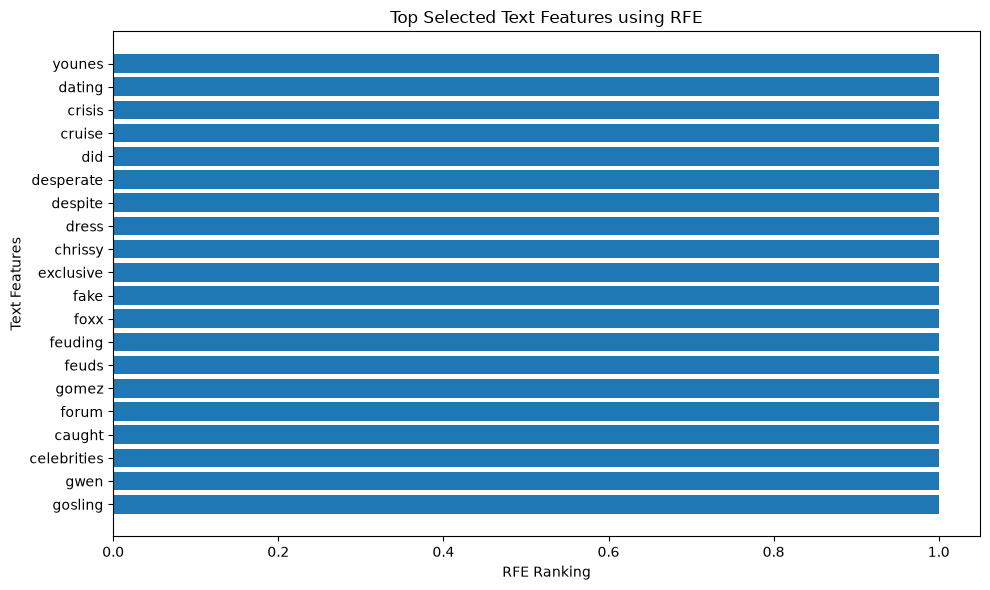

In [8]:
selected_df = feature_ranking[
    feature_ranking['Selected'] == True
].head(20)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    selected_df['Feature'],
    selected_df['Ranking']
)

plt.xlabel('RFE Ranking')
plt.ylabel('Text Features')
plt.title('Top Selected Text Features using RFE')
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

Recursive Feature Elimination (RFE) was applied to identify the most relevant text-based features for fake news classification. TF-IDF was used to convert text into numerical features, and Logistic Regression was used as the estimator.

RFE evaluated the features and selected the 100 most relevant features while eliminating less useful features. The selected features can help identify important words and patterns that contribute to distinguishing fake news from real news.